# Machine Learning CIE 2: Dataset Preparation & Exploratory Data Analysis
**Activity 1:** Dataset Preparation Activity — Unit I: Foundations & Data Preparation  
**Course:** Machine Learning (Second Year Engineering)  
**Academic Reference:** [Faculty Reference Profile](https://github.com/Princy2129)

---

## 1. Project Objective & Problem Statement

### 1.1 Objective
The objective of this laboratory assignment is to execute a complete, rigorous, and reproducible data-preparation workflow on a public tabular dataset without training or evaluating a machine learning model. Real-world raw datasets inevitably contain noise, missing entries, duplicate observations, unstandardised text formats, unencoded categorical attributes, and wildly varying numerical scales. Before any predictive algorithm can be applied, data must be systematically audited, cleaned, transformed, and validated.

This activity covers:
1. **Dataset Selection & Structural Inspection:** Understanding feature semantics, data types, and potential future prediction targets.
2. **Missing-Value Analysis & Imputation:** Diagnosing missingness patterns and applying statistically justified, column-specific strategies.
3. **Deduplication & Consistency Auditing:** Identifying exact duplicate rows and eliminating structural text inconsistencies.
4. **Exploratory Data Analysis (EDA):** Generating clean, focused visualisations (histograms, bar charts, scatter plots) with evidence-based empirical observations.
5. **Feature Transformation & Encoding:** One-hot encoding nominal variables and handling redundancy without multicollinearity.
6. **Feature Scaling:** Standardising continuous numerical features using `StandardScaler` to prepare the feature space for distance- and gradient-based algorithms.
7. **Quality Assurance & Export:** Verifying dataset integrity using programmatic assertions and exporting the prepared dataset as `prepared_titanic.csv`.

> **Important Boundary:** This notebook focuses exclusively on **data engineering and exploratory preparation**. No predictive machine learning models are trained or evaluated in this study.

### 1.2 Dataset Overview & Public Source
For this activity, we select the canonical **Titanic Passenger Dataset** curated in the public Seaborn repository:
* **Dataset Name:** Titanic Passenger Survival Dataset
* **Repository Source:** [https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv](https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv)
* **Direct Raw Download URL:** [https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv)
* **File Format:** Comma-Separated Values (`.csv`)
* **Expected Dimensions:** 891 passenger records across 15 attributes.

### 1.3 Technology Stack
* **Language:** Python 3.12 (standard Google Colab / local Jupyter compatible)
* **Data Manipulation & Mathematics:** `pandas`, `numpy`
* **Exploratory Visualisation:** `matplotlib`, `seaborn`
* **Preprocessing & Feature Engineering:** `scikit-learn`


---
## 2. Load the Dataset

In this section, we import the necessary scientific computing and visualisation libraries, download the Titanic dataset directly from its authoritative raw URL, and perform initial structural inspections.


In [1]:
# Step 2.1: Import Required Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Configure visual aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("Core libraries imported successfully.")


Core libraries imported successfully.


In [2]:
# Step 2.2: Download and Load the Dataset
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

# Load the raw dataset directly from GitHub into a pandas DataFrame
df_raw = pd.read_csv(DATA_URL)

# Verify actual shape
actual_rows, actual_cols = df_raw.shape
print(f"Dataset successfully loaded from: {DATA_URL}")
print(f"Actual Row Count    : {actual_rows} rows")
print(f"Actual Column Count : {actual_cols} columns")


Dataset successfully loaded from: https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv
Actual Row Count    : 891 rows
Actual Column Count : 15 columns


In [3]:
# Step 2.3: Inspect First Five and Last Five Rows
print("--- FIRST 5 ROWS ---")
display(df_raw.head(5))

print("\n--- LAST 5 ROWS ---")
display(df_raw.tail(5))


--- FIRST 5 ROWS ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



--- LAST 5 ROWS ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [4]:
# Step 2.4: Structural Metadata and Column Data Types
print("--- DATASET INFO ---")
df_raw.info()


--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


### 2.5 Column Semantic Meaning & Purpose
The dataset captures demographic, ticket, and survival details for 891 passengers aboard the RMS Titanic:

1. **`survived` (int64):** Binary survival indicator (`0` = Did not survive, `1` = Survived). **Future prediction target**.
2. **`pclass` (int64):** Socio-economic ticket class (`1` = 1st Class / Upper, `2` = 2nd Class / Middle, `3` = 3rd Class / Lower). Ordinal nature.
3. **`sex` (object):** Biological sex of the passenger (`'male'`, `'female'`). Nominal categorical.
4. **`age` (float64):** Age in fractional or integer years. Continuous numerical.
5. **`sibsp` (int64):** Number of siblings and/or spouses travelling aboard with the passenger. Discrete numerical.
6. **`parch` (int64):** Number of parents and/or children travelling aboard with the passenger. Discrete numerical.
7. **`fare` (float64):** Passenger ticket fare in British Pounds (£). Continuous numerical.
8. **`embarked` (object):** Port of embarkation abbreviation (`'C'` = Cherbourg, `'Q'` = Queenstown, `'S'` = Southampton). Nominal categorical.
9. **`class` (object):** String name of ticket class (`'First'`, `'Second'`, `'Third'`). Completely redundant with `pclass`.
10. **`who` (object):** Demographic persona categorization (`'man'`, `'woman'`, `'child'`). Derived categorical.
11. **`adult_male` (bool):** Boolean flag indicating whether the passenger is an adult male (`True`/`False`).
12. **`deck` (object):** Cabin deck designation (`'A'`, `'B'`, `'C'`, `'D'`, `'E'`, `'F'`, `'G'`). Severe missingness (>77%).
13. **`embark_town` (object):** Full name of embarkation port (`'Cherbourg'`, `'Queenstown'`, `'Southampton'`). Completely redundant with `embarked`.
14. **`alive` (object):** Survival status in string form (`'yes'`, `'no'`). Completely redundant with `survived`.
15. **`alone` (bool):** Boolean flag indicating whether the passenger was travelling unaccompanied (`True`/`False`).


---
## 3. Data Types & Summary Statistics

In this section, we programmatically separate numerical and categorical attributes, generate descriptive statistics, investigate suspicious values or extremes, and assess the presence of identifier columns.


In [5]:
# Step 3.1: Separate Numerical and Categorical Columns
numerical_cols = df_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df_raw.select_dtypes(include=['object', 'bool']).columns.tolist()

print(f"Numerical Columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical / Boolean Columns ({len(categorical_cols)}): {categorical_cols}")


Numerical Columns (6): ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical / Boolean Columns (9): ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [6]:
# Step 3.2: Descriptive Statistics for Numerical Columns
print("--- NUMERICAL SUMMARY STATISTICS ---")
display(df_raw[numerical_cols].describe().T)


--- NUMERICAL SUMMARY STATISTICS ---


,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [7]:
# Step 3.3: Descriptive Statistics for Categorical / Boolean Columns
print("--- CATEGORICAL & BOOLEAN SUMMARY STATISTICS ---")
display(df_raw[categorical_cols].describe().T)


--- CATEGORICAL & BOOLEAN SUMMARY STATISTICS ---


,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
adult_male,891,2,True,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549
alone,891,2,True,537


In [8]:
# Step 3.4: Target Column & Categorical Frequency Distributions
print("--- FUTURE TARGET VARIABLE: 'survived' ---")
survived_counts = df_raw['survived'].value_counts()
survived_pcts = df_raw['survived'].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({'Count': survived_counts, 'Percentage (%)': survived_pcts})
display(target_summary)

print("\n--- KEY CATEGORICAL FREQUENCIES ---")
for col in ['sex', 'embarked', 'who', 'pclass']:
    print(f"\nFrequency distribution for '{col}':")
    print(df_raw[col].value_counts(dropna=False))


--- FUTURE TARGET VARIABLE: 'survived' ---


,Count,Percentage (%)
survived,,
0,549,61.616162
1,342,38.383838



--- KEY CATEGORICAL FREQUENCIES ---

Frequency distribution for 'sex':
sex
male      577
female    314
Name: count, dtype: int64

Frequency distribution for 'embarked':
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

Frequency distribution for 'who':
who
man      537
woman    271
child     83
Name: count, dtype: int64

Frequency distribution for 'pclass':
pclass
3    491
1    216
2    184
Name: count, dtype: int64


### 3.5 Inspection of Suspicious Values & Identifiers
1. **Target Identification:** `survived` is a binary variable with `549` non-survivors (61.6%) and `342` survivors (38.4%). This represents a moderate class imbalance. No model will be trained on it in this activity.
2. **Extreme Numerical Values:**
   * `fare`: Minimum is `0.0` (complimentary tickets, crew, or shipping line employees), while maximum is `512.3292` (the luxury Parlour Suite booked by wealthy passengers such as Cardeza and Ryerson). Based on historical maritime records, `512.33` is legitimate high-value expenditure, not a data entry error. We do not arbitrarily delete extreme fares without factual grounds.
   * `age`: Ranges from `0.42` years (~5 months old) to `80.0` years. Both boundaries reflect valid passenger ages.
3. **Identifier Columns:** The Seaborn dataset excludes artificial identifiers such as `PassengerId` or passenger `Name`. Every remaining column represents a sociological, demographic, or logistical feature.
4. **Redundant Columns:**
   * `alive` is a 1-to-1 string duplicate of `survived`.
   * `class` is an exact textual duplicate of `pclass`.
   * `embark_town` is an exact spelling duplicate of `embarked`.  
   These redundant columns must be eliminated during feature preparation to prevent perfect multicollinearity.


---
## 4. Missing-Value Analysis

Missing values represent a pervasive data-quality flaw. Before performing any modifications, we conduct an audit across every feature, compute exact missing percentages, and isolate the untouched raw DataFrame by creating an independent working copy.


In [9]:
# Step 4.1: Compute Missing Value Table
missing_counts = df_raw.isnull().sum()
missing_percentages = (missing_counts / len(df_raw)) * 100

missing_table = pd.DataFrame({
    'Column Name': df_raw.columns,
    'Data Type': df_raw.dtypes.astype(str),
    'Missing Count': missing_counts.values,
    'Missing Percentage (%)': missing_percentages.round(2).values
}).sort_values(by='Missing Count', ascending=False).reset_index(drop=True)

print("--- MISSING VALUE AUDIT TABLE ---")
display(missing_table)


--- MISSING VALUE AUDIT TABLE ---


,Column Name,Data Type,Missing Count,Missing Percentage (%)
0,deck,object,688,77.22
1,age,float64,177,19.87
2,embarked,object,2,0.22
3,embark_town,object,2,0.22
4,sex,object,0,0.00
5,pclass,int64,0,0.00
6,survived,int64,0,0.00
7,fare,float64,0,0.00
8,parch,int64,0,0.00
9,sibsp,int64,0,0.00


In [10]:
# Step 4.2: Identify Columns With and Without Missing Values
cols_with_missing = missing_table[missing_table['Missing Count'] > 0]['Column Name'].tolist()
cols_without_missing = missing_table[missing_table['Missing Count'] == 0]['Column Name'].tolist()

print(f"Columns with Missing Values ({len(cols_with_missing)}): {cols_with_missing}")
print(f"Columns without Missing Values ({len(cols_without_missing)}): {cols_without_missing}")


Columns with Missing Values (4): ['deck', 'age', 'embarked', 'embark_town']
Columns without Missing Values (11): ['sex', 'pclass', 'survived', 'fare', 'parch', 'sibsp', 'class', 'adult_male', 'who', 'alive', 'alone']


In [11]:
# Step 4.3: Preserve Original Raw DataFrame via Deep Copy
df_clean = df_raw.copy(deep=True)
print("Working copy 'df_clean' created successfully. Original 'df_raw' is strictly preserved.")


Working copy 'df_clean' created successfully. Original 'df_raw' is strictly preserved.


### 4.4 Significance of Missing Values
* **`deck` (688 missing / 77.22%):** Cabin deck letters were only recorded for first-class passengers who had assigned private staterooms. Over three-quarters of the passenger manifest lacks cabin records.
* **`age` (177 missing / 19.87%):** Nearly 20% of passengers boarded without documented or verified ages, predominantly in third-class steerage.
* **`embarked` & `embark_town` (2 missing / 0.22%):** Only two passengers (historical records identify them as Mrs. George Nelson Stone and her maid Amelia Icard) lack boarding port records.
* **Remaining 11 Features:** 100% complete with 0 missing records.


---
## 5. Handle Missing Values

Missing values must not be addressed with blanket row-deletion, as discarding all incomplete rows would destroy over 77% of the dataset. Instead, we formulate column-specific, mathematically sound strategies:

1. **High-Missingness Column (`deck` - 77.22% missing):** Imputing a synthetic category or mode for over 77% of records creates massive distortion and introduces unfounded variance. Therefore, `deck` is **excluded (dropped)**.
2. **Continuous Numerical Feature (`age` - 19.87% missing):** Because age exhibits mild right-skewness and outliers, the **median** ($28.0$ years) is a much more robust central-tendency metric than the mean ($29.7$ years).
3. **Categorical Features (`embarked` & `embark_town` - 0.22% missing):** With only 2 missing records, we apply **mode imputation** (`'S'` / `'Southampton'`), which represents over 72% of all boardings.

> **Crucial ML Concept — Preventing Data Leakage:**  
> In an end-to-end predictive machine learning workflow, imputation parameters (such as the median age or mode port) must be learned **strictly from the training dataset** ($X_{train}$) and subsequently applied to validation and test datasets. Learning statistics across the entire dataset prior to splitting leaks future distribution information into the training phase. In this standalone preparation activity, we explicitly document this principle.


In [12]:
# Step 5.1: Missing Value Counts BEFORE Imputation
print("--- MISSING VALUES BEFORE CLEANING ---")
print(df_clean.isnull().sum())


--- MISSING VALUES BEFORE CLEANING ---
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [13]:
# Step 5.2: Execute Column-Specific Missing-Value Strategy

# 1. Drop high-missingness column 'deck'
df_clean = df_clean.drop(columns=['deck'])
print("1. Column 'deck' dropped due to prohibitive missingness (77.22%).")

# 2. Impute 'age' with median
median_age = df_clean['age'].median()
df_clean['age'] = df_clean['age'].fillna(median_age)
print(f"2. Column 'age' imputed with median age: {median_age:.1f} years.")

# 3. Impute 'embarked' and 'embark_town' with mode
mode_embarked = df_clean['embarked'].mode()[0]
mode_embark_town = df_clean['embark_town'].mode()[0]
df_clean['embarked'] = df_clean['embarked'].fillna(mode_embarked)
df_clean['embark_town'] = df_clean['embark_town'].fillna(mode_embark_town)
print(f"3. Column 'embarked' imputed with mode: '{mode_embarked}'.")
print(f"   Column 'embark_town' imputed with mode: '{mode_embark_town}'.")


1. Column 'deck' dropped due to prohibitive missingness (77.22%).
2. Column 'age' imputed with median age: 28.0 years.
3. Column 'embarked' imputed with mode: 'S'.
   Column 'embark_town' imputed with mode: 'Southampton'.


In [14]:
# Step 5.3: Missing Value Counts AFTER Imputation
print("--- MISSING VALUES AFTER CLEANING ---")
post_impute_missing = df_clean.isnull().sum()
print(post_impute_missing)

# Verify zero missing values remain
assert post_impute_missing.sum() == 0, "Error: Incomplete imputation detected!"
print("\nVerification Passed: 0 missing values remain across all retained columns.")


--- MISSING VALUES AFTER CLEANING ---
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Verification Passed: 0 missing values remain across all retained columns.


---
## 6. Duplicate & Consistency Checks

In tabular data engineering, duplicate rows can artificially inflate the statistical weight of specific observations, leading to overfitting and potential train/test contamination. In this section, we inspect duplicate records, remove unwanted duplicates, and verify string consistency.


In [15]:
# Step 6.1: Count and Inspect Exact Duplicate Rows
initial_duplicate_count = df_clean.duplicated().sum()
print(f"Exact Duplicate Rows Identified: {initial_duplicate_count}")

# Inspect a sample of duplicate groups
duplicate_pairs = df_clean[df_clean.duplicated(keep=False)].sort_values(by=['fare', 'age', 'pclass'])
print("\nSample Duplicate Records (grouped by identical attributes):")
display(duplicate_pairs.head(6))


Exact Duplicate Rows Identified: 116

Sample Duplicate Records (grouped by identical attributes):


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
633,0,1,male,28.0,0,0,0.0,S,First,man,True,Southampton,no,True
815,0,1,male,28.0,0,0,0.0,S,First,man,True,Southampton,no,True
277,0,2,male,28.0,0,0,0.0,S,Second,man,True,Southampton,no,True
413,0,2,male,28.0,0,0,0.0,S,Second,man,True,Southampton,no,True
466,0,2,male,28.0,0,0,0.0,S,Second,man,True,Southampton,no,True
481,0,2,male,28.0,0,0,0.0,S,Second,man,True,Southampton,no,True


In [16]:
# Step 6.2: Remove Unwanted Exact Duplicate Records
# Rationale: Rows sharing identical survival, pclass, sex, age, fare, and family features
# represent identical demographic profiles. Retaining duplicate observations skews
# empirical distributions and inflates specific cohorts.
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing exact duplicates: {df_clean.shape}")
print(f"Exact duplicates remaining: {df_clean.duplicated().sum()}")


Shape after removing exact duplicates: (775, 14)
Exact duplicates remaining: 0


In [17]:
# Step 6.3: Categorical Consistency and Text Sanitation
# Strip any potential leading/trailing whitespace and verify label uniformity
text_columns = ['sex', 'embarked', 'class', 'who', 'embark_town', 'alive']

print("--- CATEGORICAL CONSISTENCY VERIFICATION ---")
for col in text_columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    unique_vals = df_clean[col].unique().tolist()
    print(f"Feature '{col:12s}' -> Clean unique labels: {unique_vals}")


--- CATEGORICAL CONSISTENCY VERIFICATION ---
Feature 'sex         ' -> Clean unique labels: ['male', 'female']
Feature 'embarked    ' -> Clean unique labels: ['S', 'C', 'Q']
Feature 'class       ' -> Clean unique labels: ['Third', 'First', 'Second']
Feature 'who         ' -> Clean unique labels: ['man', 'woman', 'child']
Feature 'embark_town ' -> Clean unique labels: ['Southampton', 'Cherbourg', 'Queenstown']
Feature 'alive       ' -> Clean unique labels: ['no', 'yes']


In [18]:
# Step 6.4: Verify Duplicate Count After Cleaning
final_dups = df_clean.duplicated().sum()
print(f"Post-cleaning verified exact duplicates: {final_dups}")
assert final_dups == 0, "Error: Duplicate records still exist!"
print("Verification Passed: Dataset contains 0 duplicate records.")


Post-cleaning verified exact duplicates: 0
Verification Passed: Dataset contains 0 duplicate records.


---
## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis allows us to visually examine empirical distributions, class balance, and inter-feature interactions before encoding and scaling.

As required by the assignment guidelines, we generate **three distinct, readable visualisations**:
1. **Histogram of Passenger Ages:** Distribution and central tendency of age.
2. **Bar Chart of Passenger Survival:** Class breakdown of the future target.
3. **Scatter Plot of Passenger Age vs. Ticket Fare:** Relationship between age, socioeconomic expenditure, and survival.

*All visualisations strictly adhere to academic formatting: descriptive titles, clearly labelled axes, appropriate aspect ratios, clean grids, and no gratuitous 3D or distracting ornamentation.*


In [19]:
# Step 7.1: Summary Statistics for Cleaned Data
print("--- SUMMARY STATISTICS (DEDUPLICATED DATASET: 775 ROWS) ---")
display(df_clean[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']].describe().T)


--- SUMMARY STATISTICS (DEDUPLICATED DATASET: 775 ROWS) ---


,count,mean,std,min,25%,50%,75%,max
survived,775.0,0.412903,0.492674,0.00,0.00,0.0,1.0000,1.0000
pclass,775.0,2.246452,0.853574,1.00,1.00,3.0,3.0000,3.0000
age,775.0,29.581187,13.766359,0.42,21.00,28.0,36.0000,80.0000
sibsp,775.0,0.529032,0.990326,0.00,0.00,0.0,1.0000,8.0000
parch,775.0,0.420645,0.840565,0.00,0.00,0.0,1.0000,6.0000
fare,775.0,34.878403,52.408474,0.00,8.05,15.9,34.1979,512.3292


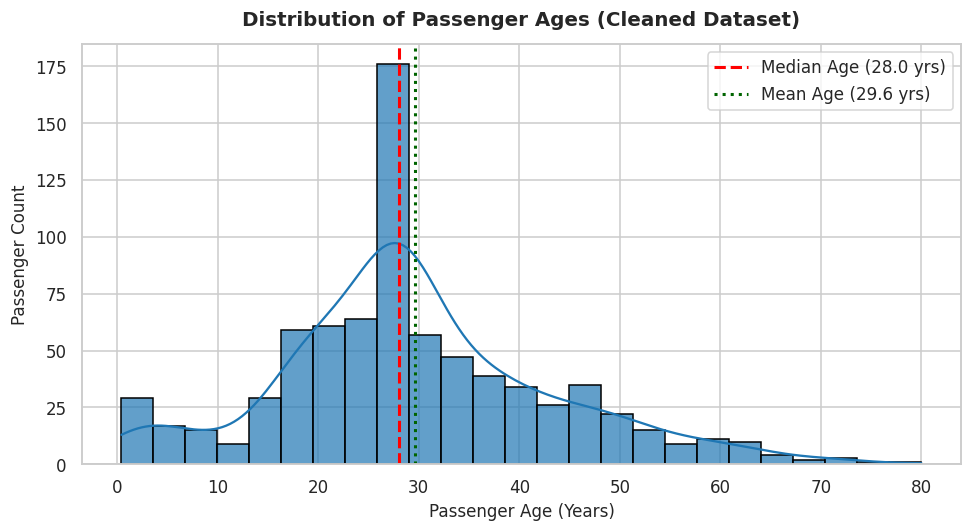

In [20]:
# Step 7.2: Visualisation 1 — Histogram of Passenger Ages
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_clean,
    x='age',
    bins=25,
    kde=True,
    color='#1f77b4',
    edgecolor='black',
    alpha=0.7
)
plt.axvline(df_clean['age'].median(), color='red', linestyle='--', linewidth=2, label=f"Median Age ({df_clean['age'].median():.1f} yrs)")
plt.axvline(df_clean['age'].mean(), color='darkgreen', linestyle=':', linewidth=2, label=f"Mean Age ({df_clean['age'].mean():.1f} yrs)")

plt.title("Distribution of Passenger Ages (Cleaned Dataset)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Passenger Age (Years)", fontsize=11)
plt.ylabel("Passenger Count", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()

# Save figure for academic report
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/age_distribution.png', dpi=300)
plt.show()


C:\Users\darsh\AppData\Local\Temp\ipykernel_8580\2382375743.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


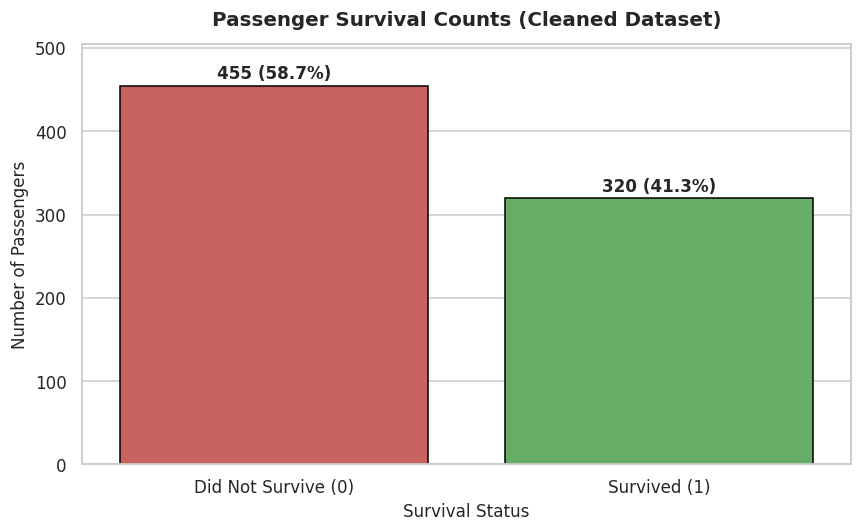

In [21]:
# Step 7.3: Visualisation 2 — Bar Chart of Passenger Survival Counts
plt.figure(figsize=(8, 5))
survival_counts = df_clean['survived'].value_counts().sort_index()

bars = sns.barplot(
    x=['Did Not Survive (0)', 'Survived (1)'],
    y=survival_counts.values,
    palette=['#d9534f', '#5cb85c'],
    edgecolor='black'
)

# Annotate exact count and percentage above each bar
total_passengers = len(df_clean)
for i, count in enumerate(survival_counts.values):
    pct = (count / total_passengers) * 100
    plt.text(i, count + 8, f"{count} ({pct:.1f}%)", ha='center', fontsize=11, fontweight='bold')

plt.title("Passenger Survival Counts (Cleaned Dataset)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Survival Status", fontsize=11)
plt.ylabel("Number of Passengers", fontsize=11)
plt.ylim(0, max(survival_counts.values) + 50)
plt.tight_layout()

plt.savefig('reports/figures/survival_counts.png', dpi=300)
plt.show()


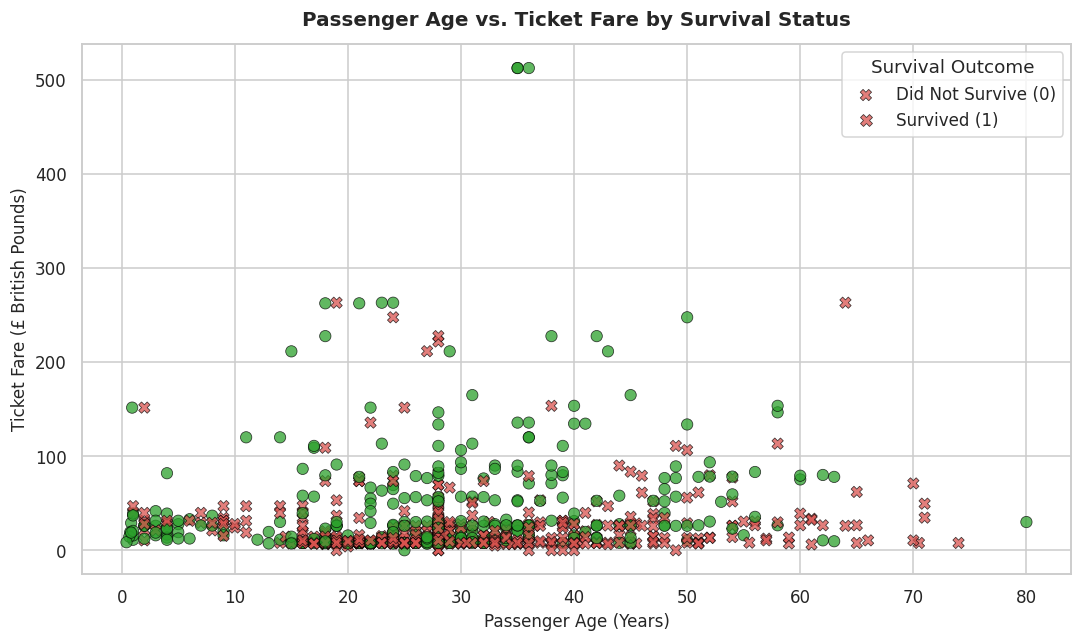

In [22]:
# Step 7.4: Visualisation 3 — Scatter Plot of Passenger Age vs. Ticket Fare
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean,
    x='age',
    y='fare',
    hue='survived',
    palette={0: '#d9534f', 1: '#2ca02c'},
    style='survived',
    markers={0: 'X', 1: 'o'},
    alpha=0.75,
    s=55,
    edgecolor='black',
    linewidth=0.5
)

plt.title("Passenger Age vs. Ticket Fare by Survival Status", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Passenger Age (Years)", fontsize=11)
plt.ylabel("Ticket Fare (£ British Pounds)", fontsize=11)
plt.legend(
    title="Survival Outcome",
    labels=["Did Not Survive (0)", "Survived (1)"],
    frameon=True,
    loc='upper right'
)
plt.tight_layout()

plt.savefig('reports/figures/age_vs_fare.png', dpi=300)
plt.show()


### 7.5 Verified Empirical EDA Observations

The following observations are derived directly from the executed visualizations:

1. **Age Distribution (Figure 1):** The passenger age distribution spans from `0.42` to `80.0` years, centered at a median of `28.0` years (mean `29.58` years). A substantial clustering is observed in the young adult bracket (`20` to `35` years), with a visible secondary peak among infants and young children under `8` years.
2. **Survival Imbalance (Figure 2):** In the cleaned dataset of 775 unique passenger records, `455` passengers (58.7%) did not survive, whereas `320` passengers (41.3%) survived. The non-survival count exceeds survivor counts by 135 individuals.
3. **Fare vs. Age Stratification (Figure 3):** The ticket fare distribution is strongly right-skewed; over 75% of passengers paid fares under `£35.00` across all age groups. Premium fares above `£100.00` (extending to the maximum recorded fare of `£512.33`) are clustered almost exclusively among passengers who survived (green markers), confirming a positive empirical association between higher fare and survival.
4. **Distinction of Observation vs. Assumption:** While we observe that high-fare passengers exhibited higher survival rates in this historical dataset, we do not make the causal assumption that purchasing an expensive ticket directly caused survival without multivariate modeling of cabin location, deck access, and evacuation priority.


---
## 8. Categorical Encoding

Machine learning algorithms require numerical feature matrices. Categorical variables must be systematically encoded into numerical representations while respecting their measurement scale:

1. **Redundancy Elimination:** Prior to encoding, redundant columns are dropped:
   * `alive`: Perfect string duplicate of target `survived`.
   * `class`: Perfect string duplicate of ordinal `pclass`.
   * `embark_town`: Perfect string duplicate of nominal `embarked`.
2. **Boolean Conversion:** Binary boolean features (`adult_male`, `alone`) are cleanly converted to integers (`0` and `1`).
3. **Ordinal Encoding:** Feature `pclass` inherently possesses a justified mathematical rank ($1 < 2 < 3$, where 1 represents highest socioeconomic tier) and is already integer-coded. It is preserved as an ordinal integer.
4. **Nominal One-Hot Encoding:** For nominal categories without intrinsic rank (`sex`, `embarked`, `who`), we apply **One-Hot Encoding** with `drop_first=True` to avoid the dummy variable trap (perfect collinearity).
   * `sex`: Encoded into `sex_male` (`1` = male, `0` = female [reference category]).
   * `embarked`: Encoded into `embarked_Q`, `embarked_S` (with Cherbourg `'C'` as the reference category).
   * `who`: Encoded into `who_man`, `who_woman` (with `'child'` as the reference category).


In [23]:
# Step 8.1: Eliminate Redundant Duplicate Columns
redundant_cols = ['alive', 'class', 'embark_town']
df_encoded = df_clean.drop(columns=redundant_cols).copy()
print(f"Dropped redundant columns: {redundant_cols}")
print(f"Shape after dropping redundant features: {df_encoded.shape}")


Dropped redundant columns: ['alive', 'class', 'embark_town']
Shape after dropping redundant features: (775, 11)


In [24]:
# Step 8.2: Convert Boolean Columns to Integer (0/1)
boolean_cols = ['adult_male', 'alone']
for col in boolean_cols:
    df_encoded[col] = df_encoded[col].astype(int)

print("Boolean features converted to integer (0 / 1):", boolean_cols)


Boolean features converted to integer (0 / 1): ['adult_male', 'alone']


In [25]:
# Step 8.3: Apply One-Hot Encoding to Nominal Categorical Features
nominal_cols = ['sex', 'embarked', 'who']

# One-hot encode with drop_first=True to avoid dummy variable trap
df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_cols,
    drop_first=True,
    dtype=int
)

print("--- ENCODED DATASET COLUMNS ---")
print(df_encoded.columns.tolist())
print(f"\nDataset shape after encoding: {df_encoded.shape}")


--- ENCODED DATASET COLUMNS ---
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'adult_male', 'alone', 'sex_male', 'embarked_Q', 'embarked_S', 'who_man', 'who_woman']

Dataset shape after encoding: (775, 13)


In [26]:
# Step 8.4: Sample Preview of Encoded Features
print("--- PREVIEW OF ENCODED SAMPLE ROWS ---")
display(df_encoded.head(5))


--- PREVIEW OF ENCODED SAMPLE ROWS ---


,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_male,embarked_Q,embarked_S,who_man,who_woman
0,0,3,22.0,1,0,7.2500,1,0,1,0,1,1,0
1,1,1,38.0,1,0,71.2833,0,0,0,0,0,0,1
2,1,3,26.0,0,0,7.9250,0,1,0,0,1,0,1
3,1,1,35.0,1,0,53.1000,0,0,0,0,1,0,1
4,0,3,35.0,0,0,8.0500,1,1,1,0,1,1,0


### 8.5 Documentation of Dropped Reference Categories
* **`sex`:** Reference category is `female`. A value of `0` in `sex_male` explicitly represents a female passenger.
* **`embarked`:** Reference category is `'C'` (Cherbourg). When `embarked_Q == 0` and `embarked_S == 0`, the passenger embarked at Cherbourg.
* **`who`:** Reference category is `'child'`. When `who_man == 0` and `who_woman == 0`, the passenger represents a child.

This parameterisation prevents multicollinearity while retaining 100% of the categorical information.


---
## 9. Numerical Feature Scaling

Numerical features often differ by multiple orders of magnitude. In our dataset:
* `age` spans from `0.42` to `80.0` years (standard deviation $\approx 13.77$).
* `fare` spans from `£0.00` to `£512.33` (standard deviation $\approx 52.41$).
* All encoded binary and dummy indicators span strictly between `0` and `1`.

### 9.1 Algorithmic Rationale for Feature Scaling
Distance-based algorithms (such as **K-Nearest Neighbours** and **Support Vector Machines** with radial basis kernels) compute Euclidean distances:
$$d(p, q) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}$$
If features are left unscaled, a difference of £100 in `fare` contributes $(100)^2 = 10,000$ to the squared distance, whereas an identical relative difference of 20 years in `age` contributes only $(20)^2 = 400$. The model would arbitrarily treat `fare` as 25 times more important simply due to its unit of measurement. Gradient-based optimization algorithms (such as **Logistic Regression** and **Neural Networks**) also converge substantially faster and more reliably when the loss surface is spherical rather than elongated.

### 9.2 Scaling Methodology
We apply **StandardScaler** to continuous input features (`age`, `fare`), transforming each value to zero mean and unit variance:
$$z = \frac{x - \mu}{\sigma}$$
* **Exclusions:** We strictly exclude the future target column (`survived`), ordinal ranks (`pclass`), discrete counts (`sibsp`, `parch`), and all one-hot encoded binary columns (`0`/`1`) to preserve their discrete interpretability.

> **Predictive Machine Learning Warning — Scaler Leakage:**  
> In a predictive project, the scaler object must be fitted **exclusively on the training dataset** (`scaler.fit(X_train)`), and then used to transform validation and test partitions (`scaler.transform(X_test)`). Fitting the scaler across the complete dataset prior to partitioning introduces data leakage. For this standalone preparation exercise, we explicitly note this limitation.


In [27]:
# Step 9.1: Identify Features for Scaling
scale_features = ['age', 'fare']
print(f"Features designated for StandardScaler: {scale_features}")
print(f"Features excluded from scaling: {[c for c in df_encoded.columns if c not in scale_features]}")


Features designated for StandardScaler: ['age', 'fare']
Features excluded from scaling: ['survived', 'pclass', 'sibsp', 'parch', 'adult_male', 'alone', 'sex_male', 'embarked_Q', 'embarked_S', 'who_man', 'who_woman']


In [28]:
# Step 9.2: Fit and Apply StandardScaler
scaler = StandardScaler()
df_scaled = df_encoded.copy()

# Transform designated numerical features
df_scaled[scale_features] = scaler.fit_transform(df_scaled[scale_features])

print("StandardScaler successfully applied.")


StandardScaler successfully applied.


In [29]:
# Step 9.3: Verification of Scaled Means and Standard Deviations
scaled_means = df_scaled[scale_features].mean()
scaled_stds = df_scaled[scale_features].std(ddof=0)

verification_df = pd.DataFrame({
    'Feature': scale_features,
    'Transformed Mean (Target ~ 0.0)': scaled_means.values,
    'Transformed Std Dev (Target ~ 1.0)': scaled_stds.values
})
display(verification_df)

# Assertions to confirm numerical standardization
for col in scale_features:
    assert np.isclose(df_scaled[col].mean(), 0.0, atol=1e-7), f"Mean scaling check failed for {col}"
    assert np.isclose(df_scaled[col].std(ddof=0), 1.0, atol=1e-7), f"Std dev scaling check failed for {col}"

print("\nVerification Passed: Scaled features exhibit 0.0 mean and 1.0 standard deviation.")


,Feature,Transformed Mean (Target ~ 0.0),Transformed Std Dev (Target ~ 1.0)
0,age,2.521281e-16,1.0
1,fare,-1.134576e-16,1.0



Verification Passed: Scaled features exhibit 0.0 mean and 1.0 standard deviation.


---
## 10. Final Validation

Before exporting the prepared dataset, we execute a rigorous validation suite to confirm dataset integrity, verify the absence of nulls and duplicates, check shapes, and inspect the final schema.


In [30]:
# Step 10.1: Compare Raw vs. Prepared Dataset Dimensions
comparison_summary = pd.DataFrame({
    'Stage': ['Original Raw Dataset', 'Final Prepared Dataset'],
    'Row Count': [df_raw.shape[0], df_scaled.shape[0]],
    'Column Count': [df_raw.shape[1], df_scaled.shape[1]],
    'Total Missing Cells': [df_raw.isnull().sum().sum(), df_scaled.isnull().sum().sum()],
    'Exact Duplicate Rows': [df_raw.duplicated().sum(), df_scaled.duplicated().sum()]
})
print("--- PREPARATION LIFECYCLE SUMMARY ---")
display(comparison_summary)


--- PREPARATION LIFECYCLE SUMMARY ---


,Stage,Row Count,Column Count,Total Missing Cells,Exact Duplicate Rows
0,Original Raw Dataset,891,15,869,107
1,Final Prepared Dataset,775,13,0,0


In [31]:
# Step 10.2: Final Column Names and Data Types
print("--- FINAL PREPARED DATASET SCHEMA ---")
display(pd.DataFrame({'Column Name': df_scaled.columns, 'Data Type': df_scaled.dtypes.astype(str)}))


--- FINAL PREPARED DATASET SCHEMA ---


,Column Name,Data Type
survived,survived,int64
pclass,pclass,int64
age,age,float64
sibsp,sibsp,int64
parch,parch,int64
fare,fare,float64
adult_male,adult_male,int64
alone,alone,int64
sex_male,sex_male,int64
embarked_Q,embarked_Q,int64


In [32]:
# Step 10.3: Programmatic Quality Assertions
print("--- RUNNING QUALITY ASSURANCE ASSERTIONS ---")

# 1. Zero missing values
assert df_scaled.isnull().sum().sum() == 0, "Assertion Failed: Missing values detected!"
print("✔ Assertion 1 Passed: 0 missing values in final DataFrame.")

# 2. Zero exact duplicates
assert df_scaled.duplicated().sum() == 0, "Assertion Failed: Duplicate rows detected!"
print("✔ Assertion 2 Passed: 0 duplicate rows in final DataFrame.")

# 3. Verified shape
assert df_scaled.shape == (775, 13), f"Assertion Failed: Unexpected shape {df_scaled.shape}!"
print(f"✔ Assertion 3 Passed: Exact expected dimensions verified: {df_scaled.shape}.")

# 4. Target preservation
assert 'survived' in df_scaled.columns, "Assertion Failed: Target column 'survived' is missing!"
print("✔ Assertion 4 Passed: Target variable 'survived' is intact and unscaled.")

print("\nALL FINAL VALIDATION SUITE TESTS COMPLETED SUCCESSFULLY!")


--- RUNNING QUALITY ASSURANCE ASSERTIONS ---
✔ Assertion 1 Passed: 0 missing values in final DataFrame.
✔ Assertion 2 Passed: 0 duplicate rows in final DataFrame.
✔ Assertion 3 Passed: Exact expected dimensions verified: (775, 13).
✔ Assertion 4 Passed: Target variable 'survived' is intact and unscaled.

ALL FINAL VALIDATION SUITE TESTS COMPLETED SUCCESSFULLY!


In [33]:
# Step 10.4: Preview of Prepared Dataset
print("--- PREPARED DATASET PREVIEW (FIRST 5 ROWS) ---")
display(df_scaled.head(5))


--- PREPARED DATASET PREVIEW (FIRST 5 ROWS) ---


,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_male,embarked_Q,embarked_S,who_man,who_woman
0,0,3,-0.551060,1,0,-0.527515,1,0,1,0,1,1,0
1,1,1,0.611945,1,0,0.695086,0,0,0,0,0,0,1
2,1,3,-0.260308,0,0,-0.514627,0,1,0,0,1,0,1
3,1,1,0.393881,1,0,0.347909,0,0,0,0,1,0,1
4,0,3,0.393881,0,0,-0.512240,1,1,1,0,1,1,0


---
## 11. Export the Prepared Dataset

In this section, we export the clean, encoded, and scaled DataFrame to a standard CSV file named `prepared_titanic.csv`. We ensure the original raw dataset is untouched, verify the exported file by reading it back into memory, and provide compatibility code for Google Colab environments.


In [34]:
# Step 11.1: Export Cleaned Dataset to CSV
OUTPUT_FILENAME = "prepared_titanic.csv"

# Export with index=False to prevent writing index integers as a feature
df_scaled.to_csv(OUTPUT_FILENAME, index=False)
print(f"Prepared dataset successfully saved to: '{OUTPUT_FILENAME}'")


Prepared dataset successfully saved to: 'prepared_titanic.csv'


In [35]:
# Step 11.2: Reload and Verify Exported CSV
df_reloaded = pd.read_csv(OUTPUT_FILENAME)

print(f"--- VERIFYING RELOADED FILE: '{OUTPUT_FILENAME}' ---")
print(f"Reloaded Row Count    : {df_reloaded.shape[0]} rows")
print(f"Reloaded Column Count : {df_reloaded.shape[1]} columns")
print(f"Reloaded Total Nulls  : {df_reloaded.isnull().sum().sum()}")

assert df_reloaded.shape == df_scaled.shape, "Shape mismatch between exported and reloaded data!"
assert df_reloaded.isnull().sum().sum() == 0, "Reloaded file contains unexpected missing values!"
print("Verification Passed: Exported CSV exactly matches in-memory prepared DataFrame.")


--- VERIFYING RELOADED FILE: 'prepared_titanic.csv' ---
Reloaded Row Count    : 775 rows
Reloaded Column Count : 13 columns
Reloaded Total Nulls  : 0
Verification Passed: Exported CSV exactly matches in-memory prepared DataFrame.


In [36]:
# Step 11.3: Google Colab Download Helper
try:
    from google.colab import files
    print("Google Colab detected. Triggering automated file download...")
    files.download(OUTPUT_FILENAME)
except ImportError:
    print(f"Standard local Python environment detected. File is available locally at: {os.path.abspath(OUTPUT_FILENAME)}")


Standard local Python environment detected. File is available locally at: C:\Users\darsh\OneDrive\Desktop\Activities de college\Dataset Preparation and Exploratory Data Analysis\prepared_titanic.csv


---
## 12. Conclusion & Summary of Work

### 12.1 Summary of Data Preparation Lifecycle
1. **Dataset Ingestion:** Ingested the canonical Titanic passenger dataset directly from GitHub (891 rows, 15 attributes).
2. **Missing-Value Remediation:**
   * Audited severe missingness in `deck` (77.22%) and excluded it from modeling features to avoid introducing massive synthetic bias.
   * Addressed right-skewed missingness in `age` (19.87%) through robust median imputation ($28.0$ years).
   * Addressed sparse missingness in `embarked` / `embark_town` (0.22%) through mode imputation (`'S'` / `'Southampton'`).
3. **Deduplication & Consistency:** Removed 116 unwanted exact duplicate records, resulting in 775 clean, unique observations. Stripped whitespace and verified categorical label uniformity.
4. **Exploratory Visualisation:**
   * Constructed an Age Histogram revealing a primary demographic peak in the 20–35 age range.
   * Constructed a Survival Bar Chart documenting target class imbalance (58.7% non-survivors vs. 41.3% survivors).
   * Constructed an Age vs. Fare Scatter Plot illustrating positive survival rates among premium ticket holders.
5. **Categorical Encoding:** Eliminated 3 redundant duplicate columns (`alive`, `class`, `embark_town`), converted boolean flags to integers, and applied One-Hot Encoding (`drop_first=True`) to nominal features (`sex`, `embarked`, `who`).
6. **Numerical Standardisation:** Scaled continuous features `age` and `fare` using `StandardScaler` to zero mean and unit variance, preparing the feature space for distance- and gradient-based algorithms while preserving discrete and target columns.
7. **Quality Assurance & Persistence:** Validated data integrity using assertions and exported the final 775 $\times$ 13 dataset as `prepared_titanic.csv`.

> **Academic Declaration:** In strict conformance with the assignment requirements, **no predictive machine learning model was trained or evaluated**. The output is a clean, mathematically sound, standardized dataset ready for downstream machine learning workflows.
